<a href="https://colab.research.google.com/github/fabianrubioai/financial-volatility-analyzer/blob/main/financial_volatility_analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# Install required packages
!pip install yfinance matplotlib pandas numpy

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set clean visualization style
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')

# Define assets and date range (S&P 500, Apple, Microsoft)
tickers = ['^GSPC', 'AAPL', 'MSFT']
start_date = '2023-01-01'
end_date = '2026-10-01'

# Download adjusted closing prices (using auto_adjust=True and 'Close')
print("Downloading market data...")
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)['Close']

print("\n--- Data Download Successful! ---")
data.head()

[*********************100%***********************]  3 of 3 completed


--- Data Download Successful! ---


Ticker,AAPL,MSFT,^GSPC
Date,,,
2023-01-03,122.876740,232.510544,3824.139893
2023-01-04,124.144142,222.339783,3852.969971
2023-01-05,122.827621,215.750168,3808.100098
2023-01-06,127.346962,218.292862,3895.080078
2023-01-09,127.867668,220.418198,3892.090088


In [16]:
print("-Daily Volatility (%): The average day-to-day fluctuation of the asset.\n"
      "-Annualized Volatility (%): The standard industry measure for annualized risk (scaling daily risk by √252).\n"
      "-Annualized Return (%): The compound annual growth rate based on daily log returns.")

# Calculate daily logarithmic returns: ln(P_t / P_{t-1})
log_returns = np.log(data / data.shift(1)).dropna()

# Calculate daily volatility (standard deviation of daily log returns)
daily_volatility = log_returns.std()

# Calculate annualized volatility (assuming 252 trading days per year)
annualized_volatility = daily_volatility * np.sqrt(252)

# Calculate annualized mean return
annualized_returns = log_returns.mean() * 252

# Create a summary metrics table
metrics_summary = pd.DataFrame({
    'Daily Volatility (%)': daily_volatility * 100,
    'Annualized Volatility (%)': annualized_volatility * 100,
    'Annualized Return (%)': annualized_returns * 100
})
print()
print("--- Volatility & Return Analysis ---")
print()
metrics_summary.round(2)

-Daily Volatility (%): The average day-to-day fluctuation of the asset.
-Annualized Volatility (%): The standard industry measure for annualized risk (scaling daily risk by √252).
-Annualized Return (%): The compound annual growth rate based on daily log returns.

--- Volatility & Return Analysis ---



,Daily Volatility (%),Annualized Volatility (%),Annualized Return (%)
Ticker,,,
AAPL,1.62,25.72,26.79
MSFT,1.65,26.15,21.25
^GSPC,0.92,14.67,18.63


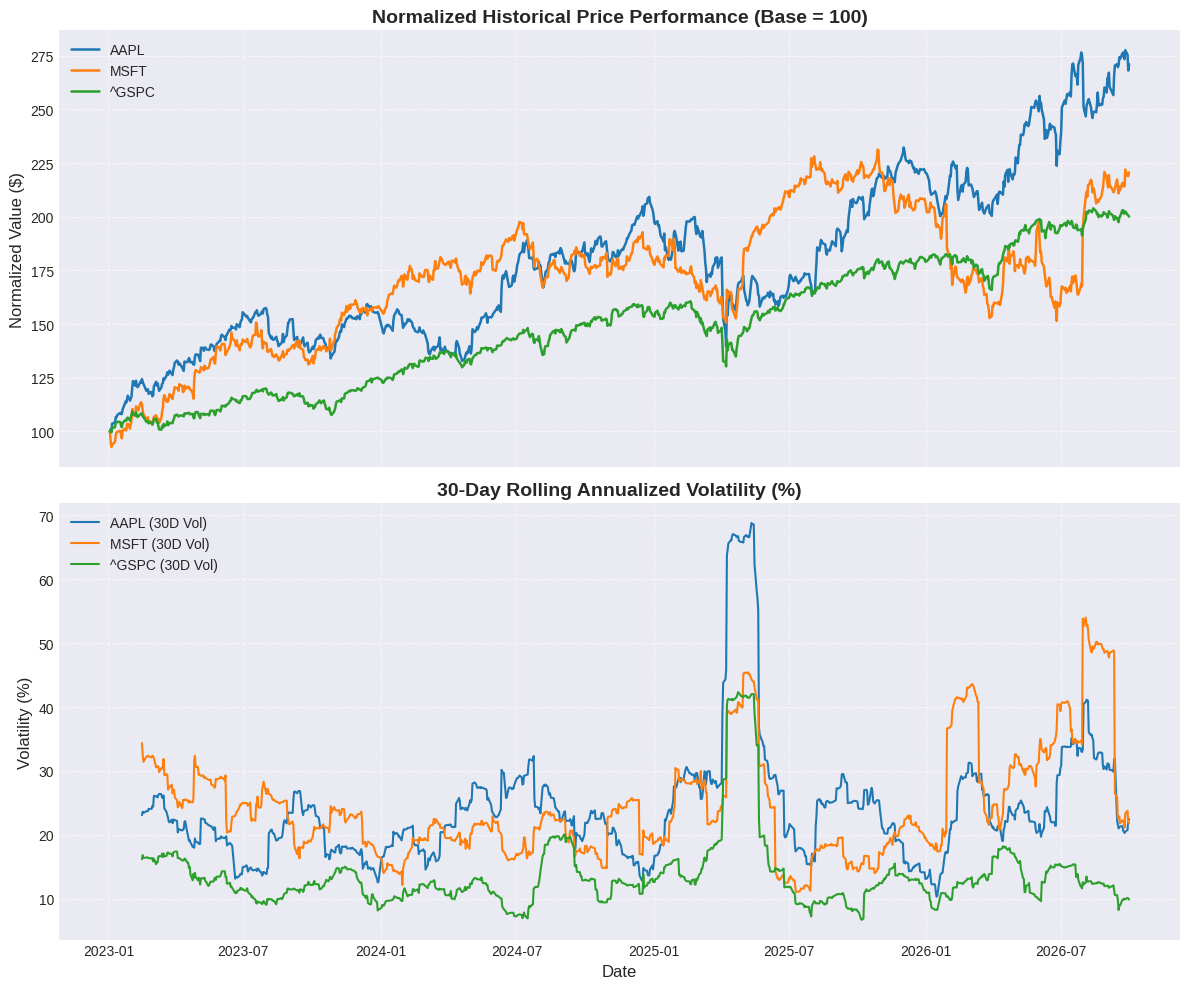

In [17]:
# --- Data Visualizations ---

# 1. Calculate 30-day rolling annualized volatility (%)
rolling_volatility = log_returns.rolling(window=30).std() * np.sqrt(252) * 100

# 2. Calculate normalized price performance (Base = 100)
normalized_prices = (data / data.iloc[0]) * 100

# 3. Create subplots for Price Performance and Rolling Volatility
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot 1: Cumulative Performance
for col in normalized_prices.columns:
    ax1.plot(normalized_prices.index, normalized_prices[col], label=col, linewidth=1.8)

ax1.set_title('Normalized Historical Price Performance (Base = 100)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Normalized Value ($)', fontsize=12)
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: 30-Day Rolling Volatility
for col in rolling_volatility.columns:
    ax2.plot(rolling_volatility.index, rolling_volatility[col], label=f'{col} (30D Vol)', linewidth=1.5)

ax2.set_title('30-Day Rolling Annualized Volatility (%)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Date', fontsize=12)
ax2.set_ylabel('Volatility (%)', fontsize=12)
ax2.legend(loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()